In [11]:
import json, sys, time
from pathlib import Path

import numpy as np
import pandas as pd

import matplotlib.pyplot as plt

pd.set_option("display.max_columns", 100)

In [12]:
SEED = 42
N_JOBS = 8

DI_COLAB = "google.colab" in sys.modules
BASE = Path("/content/drive/MyDrive/uts-ml") if DI_COLAB else Path.cwd().parent
DATA = Path("/content/data") if DI_COLAB else BASE / "data"
HASIL = BASE / "kode" / "hasil"
CACHE = HASIL / "cache"
CACHE.mkdir(parents=True, exist_ok=True)

KOLOM_KATEGORI = ["layanan", "mitra_kurir", "hub_asal", "kota_asal",
                  "pulau_tujuan", "kota_tujuan"]
print(BASE, DATA, sep="\n")

c:\Users\Coook1es\Documents\kuliah\Semester7\ML\UTSasli\uts-ml
c:\Users\Coook1es\Documents\kuliah\Semester7\ML\UTSasli\uts-ml\data


In [13]:
def _optimasi_dtype(df):
    kolom_float = df.select_dtypes("float64").columns
    df[kolom_float] = df[kolom_float].astype("float32")
    return df


def _baca_satu(nama):
    parquet = CACHE / f"{nama}.parquet"
    if parquet.exists():
        return pd.read_parquet(parquet)

    df = pd.read_csv(
        DATA / f"{nama}.csv",
        parse_dates=["tgl_pickup"],
        dtype={k: "category" for k in KOLOM_KATEGORI},
    )
    df = _optimasi_dtype(df)
    df.to_parquet(parquet, index=False)
    return df


def baca_regresi():
    return _baca_satu("regresi_train"), _baca_satu("regresi_test")

In [14]:
def pinball(y, q, alpha):
    y = np.asarray(y, dtype=float)
    q = np.asarray(q, dtype=float)
    e = y - q
    return float(np.mean(np.maximum(alpha * e, (alpha - 1) * e)))


def coverage(y, p90):
    return float(np.mean(np.asarray(y) <= np.asarray(p90)))

In [15]:
def _ke_python(x):
    if isinstance(x, np.integer):
        return int(x)
    if isinstance(x, np.floating):
        return float(x)
    if isinstance(x, (pd.Timestamp, np.datetime64)):
        return str(x)
    raise TypeError(f"Tidak bisa disimpan: {type(x)}")


def simpan_hasil(nama, data):
    path = HASIL / f"{nama}.json"
    lama = json.loads(path.read_text(encoding="utf-8")) if path.exists() else {}
    lama.update(data)
    path.write_text(json.dumps(lama, indent=1, ensure_ascii=False, default=_ke_python),
                    encoding="utf-8")

In [16]:
from sklearn.metrics import mean_pinball_loss

y = np.array([10, 20]); q = np.array([12, 15])
for a in [0.9, 0.5]:
    print(a, pinball(y, q, a), mean_pinball_loss(y, q, alpha=a))
print("coverage:", coverage(y, q))

0.9 2.35 2.35
0.5 1.75 1.75
coverage: 0.5


In [17]:
t0 = time.time()
mentah = pd.read_csv(DATA / "regresi_train.csv")
detik_csv = time.time() - t0
mb_mentah = mentah.memory_usage(deep=True).sum() / 1e6
del mentah

t0 = time.time()
train, test = baca_regresi()
detik_fungsi = time.time() - t0
mb_opt = train.memory_usage(deep=True).sum() / 1e6

print(f"CSV mentah  : {detik_csv:.1f} s, {mb_mentah:.0f} MB")
print(f"baca_regresi: {detik_fungsi:.1f} s, {mb_opt:.0f} MB")

CSV mentah  : 0.5 s, 165 MB
baca_regresi: 0.2 s, 85 MB


In [18]:
print("train:", train.shape, "| test:", test.shape)
print("durasi_jam ada di test?", "durasi_jam" in test.columns)
print("rentang train:", train["tgl_pickup"].min().date(), "s/d", train["tgl_pickup"].max().date())
print("rentang test :", test["tgl_pickup"].min().date(), "s/d", test["tgl_pickup"].max().date())

level = pd.DataFrame({"train": train[KOLOM_KATEGORI].nunique(),
                      "test":  test[KOLOM_KATEGORI].nunique()})
level_baru = {k: sorted(set(test[k].unique()) - set(train[k].unique()))
              for k in KOLOM_KATEGORI}
level["baru_di_test"] = [len(level_baru[k]) for k in KOLOM_KATEGORI]
print(level_baru)
level

train: (250000, 77) | test: (60000, 76)
durasi_jam ada di test? False
rentang train: 2025-01-01 s/d 2025-08-31
rentang test : 2025-09-01 s/d 2025-10-31
{'layanan': [], 'mitra_kurir': ['K13'], 'hub_asal': [], 'kota_asal': [], 'pulau_tujuan': [], 'kota_tujuan': []}


,train,test,baru_di_test
layanan,4,4,0
mitra_kurir,12,13,1
hub_asal,6,6,0
kota_asal,30,30,0
pulau_tujuan,7,7,0
kota_tujuan,405,405,0


In [19]:
simpan_hasil("tugas1", {"tahap0": {
    "n_train": len(train), "n_test": len(test),
    "mb_mentah": mb_mentah, "mb_opt": mb_opt,
    "rentang_train": [str(train["tgl_pickup"].min().date()), str(train["tgl_pickup"].max().date())],
    "rentang_test":  [str(test["tgl_pickup"].min().date()),  str(test["tgl_pickup"].max().date())],
    "level_kategori": level["train"].to_dict(),
    "level_baru_di_test": level_baru,
}})

count    250000.0
mean         77.8
std         207.7
min          11.6
50%          61.7
90%         117.8
99%         224.7
99.9%      3054.0
max       25452.0
Name: durasi_jam, dtype: float64


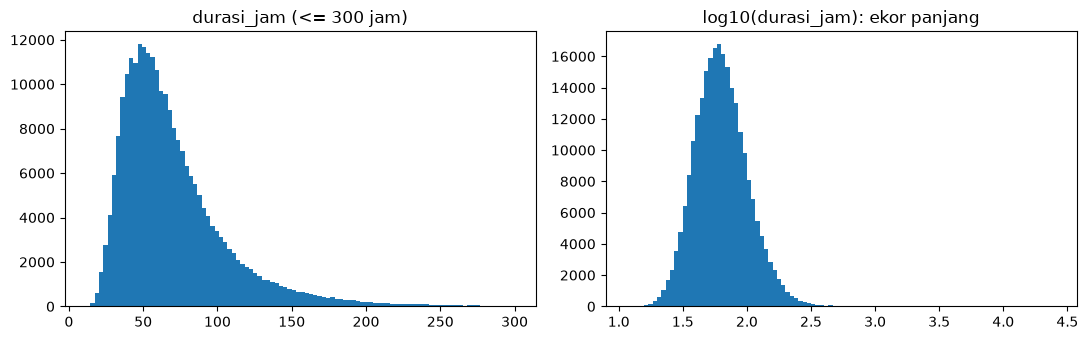

In [20]:
GAMBAR = HASIL / "gambar"
GAMBAR.mkdir(parents=True, exist_ok=True)

y = train["durasi_jam"]
print(y.describe(percentiles=[.5, .9, .99, .999]).round(1))

fig, ax = plt.subplots(1, 2, figsize=(11, 3.5))
ax[0].hist(y[y <= 300], bins=100)
ax[0].set_title("durasi_jam (<= 300 jam)")
ax[1].hist(np.log10(y), bins=100)
ax[1].set_title("log10(durasi_jam): ekor panjang")
fig.tight_layout()
fig.savefig(GAMBAR / "a_distribusi_target.png", dpi=120)
plt.show()

In [21]:
BATAS = 1000
ekstrem = y > BATAS
porsi6_ekstrem = (y[ekstrem] % 6 == 0).mean()
porsi6_normal  = (y[~ekstrem] % 6 == 0).mean()

waktu_tiba = (train["tgl_pickup"]
              + pd.to_timedelta(train["jam_pickup"], unit="h")
              + pd.to_timedelta(y, unit="h"))
lewat_tarik = waktu_tiba >= pd.Timestamp("2025-09-01")

print(f"durasi > {BATAS} jam       : {ekstrem.sum()} baris")
print(f"kelipatan 6 (ekstrem/normal): {porsi6_ekstrem:.0%} vs {porsi6_normal:.1%}")
print(f"tiba setelah data ditarik  : {lewat_tarik.sum()} baris")
print(f"irisan keduanya            : {(ekstrem & lewat_tarik).sum()} baris")

durasi > 1000 jam       : 370 baris
kelipatan 6 (ekstrem/normal): 100% vs 1.6%
tiba setelah data ditarik  : 2804 baris
irisan keduanya            : 256 baris


In [22]:
kosong = train.isna().mean()
print(kosong[kosong > 0])

berat_kosong = train["berat_kg"].isna()
print(f"median durasi, berat kosong: {y[berat_kosong].median():.1f} jam")
print(f"median durasi, berat terisi: {y[~berat_kosong].median():.1f} jam")

berat_kg    0.055588
dtype: float64
median durasi, berat kosong: 71.4 jam
median durasi, berat terisi: 61.1 jam


In [23]:
for kol in ["jarak_km", "antrean_hub_asal"]:
    print(f"{kol:17s} =0: {(train[kol] == 0).sum():5d} | =9999 train: {(train[kol] == 9999).sum()} "
          f"| =9999 test: {(test[kol] == 9999).sum()}")
wajar = train["jarak_km"].between(1, 9998)
print("jarak terjauh yang wajar:", train.loc[wajar, "jarak_km"].max())

jarak_km          =0:   703 | =9999 train: 456 | =9999 test: 130
antrean_hub_asal  =0:  1089 | =9999 train: 1 | =9999 test: 0
jarak terjauh yang wajar: 6031.5


In [24]:
numerik = [c for c in test.columns if pd.api.types.is_numeric_dtype(test[c])]
geser = pd.DataFrame({"mean_train": train[numerik].mean(),
                      "mean_test":  test[numerik].mean()})
geser["smd"] = (geser["mean_test"] - geser["mean_train"]) / train[numerik].std()
geser = geser.reindex(geser["smd"].abs().sort_values(ascending=False).index)
display(geser.head(6).round(2))

print("median jumlah_scan per bulan, train:",
      train.groupby(train["tgl_pickup"].dt.month)["jumlah_scan"].median().to_dict())
print("median jumlah_scan per bulan, test :",
      test.groupby(test["tgl_pickup"].dt.month)["jumlah_scan"].median().to_dict())

hari = (train["tgl_pickup"] - train["tgl_pickup"].min()).dt.days
fitur_f = [f"f{i:02d}" for i in range(1, 51)]
kor = pd.DataFrame({
    "vs_waktu":  [train[f].corr(hari, method="spearman") for f in fitur_f],
    "vs_target": [train[f].corr(y, method="spearman") for f in fitur_f],
}, index=fitur_f)
display(kor[kor["vs_waktu"].abs() > 0.1].round(3))

,mean_train,mean_test,smd
jumlah_scan,9.65,1.50,-1.45
f30,0.50,1.09,0.57
f35,1.01,1.03,0.26
f17,0.26,0.35,0.20
antrean_hub_asal,3328.68,4618.88,0.18
hujan_tujuan_mm,8.00,7.31,-0.04


median jumlah_scan per bulan, train: {1: 8.0, 2: 8.0, 3: 9.0, 4: 8.0, 5: 8.0, 6: 8.0, 7: 9.0, 8: 8.0}
median jumlah_scan per bulan, test : {9: 1.0, 10: 1.0}


,vs_waktu,vs_target
f30,0.266,-0.004
f41,-0.139,0.064


In [25]:
import lightgbm as lgb

bersih = train[~ekstrem & ~lewat_tarik].copy()
latih = bersih[bersih["tgl_pickup"] <  "2025-07-01"]
valid = bersih[bersih["tgl_pickup"] >= "2025-07-01"]
SEMUA_FITUR = [c for c in train.columns if c not in ("id_paket", "tgl_pickup", "durasi_jam")]


def latih_lgb(fitur, df_latih, df_valid, alpha):
    model = lgb.LGBMRegressor(objective="quantile", alpha=alpha, n_estimators=300,
                              learning_rate=0.05, num_leaves=63,
                              random_state=SEED, n_jobs=N_JOBS, verbose=-1)
    model.fit(df_latih[fitur], df_latih["durasi_jam"])
    return model.predict(df_valid[fitur])


def evaluasi(fitur, df_valid=None):
    df_valid = valid if df_valid is None else df_valid
    p50 = latih_lgb(fitur, latih, df_valid, 0.5)
    p90 = latih_lgb(fitur, latih, df_valid, 0.9)
    yv = valid["durasi_jam"]
    return {"pinball50": pinball(yv, p50, 0.5),
            "pinball90": pinball(yv, p90, 0.9),
            "coverage90": coverage(yv, p90)}


tanpa_scan = [c for c in SEMUA_FITUR if c != "jumlah_scan"]
rng = np.random.default_rng(SEED)
valid_seperti_uji = valid.copy()
valid_seperti_uji["jumlah_scan"] = rng.choice(test["jumlah_scan"].to_numpy(), size=len(valid))

dampak = pd.DataFrame({
    "dengan jumlah_scan":                       evaluasi(SEMUA_FITUR),
    "dengan jumlah_scan, nilai seperti di uji": evaluasi(SEMUA_FITUR, valid_seperti_uji),
    "tanpa jumlah_scan":                        evaluasi(tanpa_scan),
    "tanpa jumlah_scan & f30":                  evaluasi([c for c in tanpa_scan if c != "f30"]),
}).T.round(3)
dampak

,pinball50,pinball90,coverage90
dengan jumlah_scan,5.362,2.947,0.876
"dengan jumlah_scan, nilai seperti di uji",10.940,13.574,0.439
tanpa jumlah_scan,6.755,4.340,0.874
tanpa jumlah_scan & f30,6.758,4.337,0.874


In [26]:
def bersihkan(df):
    df = df.copy()
    df.loc[df["jarak_km"].isin([0, 9999]), "jarak_km"] = np.nan
    df["berat_kosong"] = df["berat_kg"].isna().astype("int8")
    return df

bersih = bersihkan(bersih)
test_b = bersihkan(test)
DIBUANG = ["jumlah_scan", "f30"]
FITUR = [c for c in SEMUA_FITUR if c not in DIBUANG] + ["berat_kosong"]
print(len(bersih), "baris latih |", len(FITUR), "fitur")

simpan_hasil("tugas1", {"audit": {
    "target": y.describe(percentiles=[.5, .9, .99, .999]).round(2).to_dict(),
    "label_ekstrem": int(ekstrem.sum()),
    "porsi_kelipatan6_ekstrem": porsi6_ekstrem, "porsi_kelipatan6_normal": porsi6_normal,
    "label_lewat_tarik": int(lewat_tarik.sum()),
    "n_latih_bersih": len(bersih),
    "berat_kosong_porsi": float(berat_kosong.mean()),
    "median_durasi_berat_kosong": float(y[berat_kosong].median()),
    "median_durasi_berat_terisi": float(y[~berat_kosong].median()),
    "jarak_0": int((train["jarak_km"] == 0).sum()), "jarak_9999": int((train["jarak_km"] == 9999).sum()),
    "pergeseran_smd": geser["smd"].head(6).round(3).to_dict(),
    "dampak": dampak.to_dict(orient="index"),
    "fitur_dibuang": DIBUANG,
}})

247082 baris latih | 73 fitur


In [27]:
LIPATAN_WAKTU = [
    ("Jan-Apr -> Mei-Jun", "2025-01-01", "2025-05-01", "2025-07-01"),
    ("Jan-Jun -> Jul-Agu", "2025-01-01", "2025-07-01", "2025-09-01"),
]


def potong_waktu(df, mulai, batas, akhir):
    t = df["tgl_pickup"]
    return df[(t >= mulai) & (t < batas)], df[(t >= batas) & (t < akhir)]


def nilai_lipatan(df_latih, df_valid, fitur=FITUR):
    p50 = latih_lgb(fitur, df_latih, df_valid, 0.5)
    p90 = latih_lgb(fitur, df_latih, df_valid, 0.9)
    yv = df_valid["durasi_jam"]
    return {"pinball50": pinball(yv, p50, 0.5),
            "pinball90": pinball(yv, p90, 0.9),
            "coverage90": coverage(yv, p90)}


hasil_waktu = {}
for nama, mulai, batas, akhir in LIPATAN_WAKTU:
    df_latih, df_valid = potong_waktu(bersih, mulai, batas, akhir)
    hasil_waktu[nama] = nilai_lipatan(df_latih, df_valid)
    print(nama, len(df_latih), len(df_valid),
          {k: round(v, 3) for k, v in hasil_waktu[nama].items()})

Jan-Apr -> Mei-Jun 116447 64683 {'pinball50': 6.507, 'pinball90': 4.274, 'coverage90': 0.903}
Jan-Jun -> Jul-Agu 181130 65952 {'pinball50': 6.743, 'pinball90': 4.328, 'coverage90': 0.876}


In [28]:
from sklearn.model_selection import KFold

kf = KFold(n_splits=5, shuffle=True, random_state=SEED)
hasil_acak = []
for idx_latih, idx_valid in kf.split(bersih):
    hasil_acak.append(nilai_lipatan(bersih.iloc[idx_latih], bersih.iloc[idx_valid]))

banding = pd.DataFrame({
    "CV acak (5-fold)":               pd.DataFrame(hasil_acak).mean(),
    "CV waktu (rata-rata 2 lipatan)": pd.DataFrame(hasil_waktu).T.mean(),
    "lipatan terakhir: Jul-Agu":      hasil_waktu["Jan-Jun -> Jul-Agu"],
}).T.round(3)
print("sebaran antar fold CV acak (std):", pd.DataFrame(hasil_acak).std().round(3).to_dict())
banding

sebaran antar fold CV acak (std): {'pinball50': 0.039, 'pinball90': 0.023, 'coverage90': 0.001}


,pinball50,pinball90,coverage90
CV acak (5-fold),6.639,4.302,0.883
CV waktu (rata-rata 2 lipatan),6.625,4.301,0.889
lipatan terakhir: Jul-Agu,6.743,4.328,0.876


In [29]:
simpan_hasil("tugas1", {"validasi": {
    "lipatan_waktu": {nama: {"latih": [m, b], "valid": [b, a]} for nama, m, b, a in LIPATAN_WAKTU},
    "per_lipatan_waktu": hasil_waktu,
    "cv_acak_per_fold": hasil_acak,
    "banding": banding.to_dict(orient="index"),
}})

In [30]:
def skor(yv, p50, p90):
    return {"pinball50": pinball(yv, p50, 0.5),
            "pinball90": pinball(yv, p90, 0.9),
            "coverage90": coverage(yv, p90)}


def evaluasi_model(fungsi_prediksi):
    hasil = {}
    for nama, mulai, batas, akhir in LIPATAN_WAKTU:
        df_latih, df_valid = potong_waktu(bersih, mulai, batas, akhir)
        p50, p90 = fungsi_prediksi(df_latih, df_valid)
        hasil[nama] = skor(df_valid["durasi_jam"], p50, p90)
    hasil["rata-rata"] = pd.DataFrame(hasil).T.mean().to_dict()
    return hasil

In [31]:
GRUP = ["layanan", "pulau_tujuan"]


def prediksi_baseline(df_latih, df_valid):
    tabel = (df_latih.groupby(GRUP, observed=True)["durasi_jam"]
             .quantile([0.5, 0.9]).unstack())
    tabel.columns = ["p50", "p90"]
    gabung = df_valid[GRUP].merge(tabel, left_on=GRUP, right_index=True, how="left")
    p50 = gabung["p50"].fillna(df_latih["durasi_jam"].median()).to_numpy()
    p90 = gabung["p90"].fillna(df_latih["durasi_jam"].quantile(0.9)).to_numpy()
    return p50, p90


hasil_model = {"Baseline: kuantil per layanan x pulau": evaluasi_model(prediksi_baseline)}
hasil_model["Baseline: kuantil per layanan x pulau"]["rata-rata"]

{'pinball50': 10.12016253475275,
 'pinball90': 6.212082057882467,
 'coverage90': 0.9003949843364417}

In [32]:
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.linear_model import Ridge

NUMERIK = [c for c in FITUR if c not in KOLOM_KATEGORI]


def buat_ridge(alpha):
    praproses = ColumnTransformer([
        ("num", make_pipeline(SimpleImputer(strategy="median"), StandardScaler()), NUMERIK),
        ("kat", OneHotEncoder(handle_unknown="ignore"), KOLOM_KATEGORI),
    ])
    return make_pipeline(praproses, Ridge(alpha=alpha))


def prediksi_ridge(df_latih, df_valid, alpha=1.0):
    model = buat_ridge(alpha)
    y_log = np.log1p(df_latih["durasi_jam"])
    model.fit(df_latih[FITUR], y_log)
    residu = y_log - model.predict(df_latih[FITUR])
    pred_log = model.predict(df_valid[FITUR])
    p50 = np.expm1(pred_log + residu.quantile(0.5))
    p90 = np.expm1(pred_log + residu.quantile(0.9))
    return p50, p90


tuning_ridge = {a: evaluasi_model(lambda l, v: prediksi_ridge(l, v, a))["rata-rata"]
                for a in [1.0, 10.0, 100.0]}
display(pd.DataFrame(tuning_ridge).T.round(3))
ALPHA_RIDGE = min(tuning_ridge, key=lambda a: tuning_ridge[a]["pinball50"])
hasil_model["Ridge pada log(durasi)"] = evaluasi_model(lambda l, v: prediksi_ridge(l, v, ALPHA_RIDGE))
print("alpha terbaik:", ALPHA_RIDGE)

,pinball50,pinball90,coverage90
1.0,7.345,4.466,0.909
10.0,7.347,4.467,0.909
100.0,7.401,4.493,0.910


alpha terbaik: 1.0


In [33]:
import itertools

def latih_lgb_param(df_latih, df_valid, alpha, param):
    model = lgb.LGBMRegressor(objective="quantile", alpha=alpha, learning_rate=0.05,
                              random_state=SEED, n_jobs=N_JOBS, verbose=-1, **param)
    model.fit(df_latih[FITUR], df_latih["durasi_jam"])
    return model.predict(df_valid[FITUR])


GRID = [dict(num_leaves=nl, min_child_samples=mc, n_estimators=ne)
        for nl, mc, ne in itertools.product([31, 127], [50, 300], [300, 600])]

CACHE_TUNING = CACHE / "tuning_lgb.json"
if CACHE_TUNING.exists():
    hasil_tuning = json.loads(CACHE_TUNING.read_text(encoding="utf-8"))
else:
    hasil_tuning = []
    for param in GRID:
        h = evaluasi_model(lambda l, v: (latih_lgb_param(l, v, 0.5, param),
                                         latih_lgb_param(l, v, 0.9, param)))
        hasil_tuning.append({**param, **h["rata-rata"]})
        print(param, round(h["rata-rata"]["pinball50"], 3), round(h["rata-rata"]["pinball90"], 3))
    CACHE_TUNING.write_text(json.dumps(hasil_tuning, indent=1), encoding="utf-8")

tabel_tuning = pd.DataFrame(hasil_tuning)
display(tabel_tuning.round(3))

KUNCI = ["num_leaves", "min_child_samples", "n_estimators"]
PARAM_P50 = tabel_tuning.loc[tabel_tuning["pinball50"].idxmin(), KUNCI].astype(int).to_dict()
PARAM_P90 = tabel_tuning.loc[tabel_tuning["pinball90"].idxmin(), KUNCI].astype(int).to_dict()
print("terbaik untuk P50:", PARAM_P50)
print("terbaik untuk P90:", PARAM_P90)

{'num_leaves': 31, 'min_child_samples': 50, 'n_estimators': 300} 6.645 4.272
{'num_leaves': 31, 'min_child_samples': 50, 'n_estimators': 600} 6.613 4.273
{'num_leaves': 31, 'min_child_samples': 300, 'n_estimators': 300} 6.641 4.272
{'num_leaves': 31, 'min_child_samples': 300, 'n_estimators': 600} 6.607 4.271
{'num_leaves': 127, 'min_child_samples': 50, 'n_estimators': 300} 6.612 4.324
{'num_leaves': 127, 'min_child_samples': 50, 'n_estimators': 600} 6.596 4.353
{'num_leaves': 127, 'min_child_samples': 300, 'n_estimators': 300} 6.613 4.303
{'num_leaves': 127, 'min_child_samples': 300, 'n_estimators': 600} 6.601 4.325


,num_leaves,min_child_samples,n_estimators,pinball50,pinball90,coverage90
0,31,50,300,6.645,4.272,0.895
1,31,50,600,6.613,4.273,0.891
2,31,300,300,6.641,4.272,0.895
3,31,300,600,6.607,4.271,0.890
4,127,50,300,6.612,4.324,0.883
5,127,50,600,6.596,4.353,0.871
6,127,300,300,6.613,4.303,0.884
7,127,300,600,6.601,4.325,0.876


terbaik untuk P50: {'num_leaves': 127, 'min_child_samples': 50, 'n_estimators': 600}
terbaik untuk P90: {'num_leaves': 31, 'min_child_samples': 300, 'n_estimators': 600}


In [34]:
hasil_model["LightGBM kuantil (default)"] = evaluasi_model(
    lambda l, v: (latih_lgb(FITUR, l, v, 0.5), latih_lgb(FITUR, l, v, 0.9)))
hasil_model["LightGBM kuantil (dituning)"] = evaluasi_model(
    lambda l, v: (latih_lgb_param(l, v, 0.5, PARAM_P50), latih_lgb_param(l, v, 0.9, PARAM_P90)))

banding_model = pd.DataFrame({m: h["rata-rata"] for m, h in hasil_model.items()}).T.round(3)
banding_model

,pinball50,pinball90,coverage90
Baseline: kuantil per layanan x pulau,10.120,6.212,0.900
Ridge pada log(durasi),7.345,4.466,0.909
LightGBM kuantil (default),6.625,4.301,0.889
LightGBM kuantil (dituning),6.596,4.271,0.890


In [35]:
simpan_hasil("tugas1", {"model": {
    "banding": banding_model.to_dict(orient="index"),
    "per_lipatan": {m: {k: v for k, v in h.items() if k != "rata-rata"} for m, h in hasil_model.items()},
    "ridge_alpha": {str(a): v for a, v in tuning_ridge.items()},
    "ridge_alpha_terbaik": ALPHA_RIDGE,
    "tuning_lgb": hasil_tuning,
    "param_p50": PARAM_P50, "param_p90": PARAM_P90,
}})

In [36]:
from sklearn.preprocessing import TargetEncoder
from sklearn.model_selection import KFold


def prediksi_native(df_latih, df_valid, fitur=FITUR):
    return latih_lgb(fitur, df_latih, df_valid, 0.5), latih_lgb(fitur, df_latih, df_valid, 0.9)


def prediksi_target_enc(df_latih, df_valid):
    enc = TargetEncoder(target_type="continuous", cv=KFold(5, shuffle=True, random_state=SEED))
    lat, val = df_latih.copy(), df_valid.copy()
    lat["kota_tujuan_te"] = enc.fit_transform(lat[["kota_tujuan"]], np.log1p(lat["durasi_jam"])).ravel()
    val["kota_tujuan_te"] = enc.transform(val[["kota_tujuan"]]).ravel()
    fitur = [c for c in FITUR if c != "kota_tujuan"] + ["kota_tujuan_te"]
    return prediksi_native(lat, val, fitur)


tanpa_kota = [c for c in FITUR if c != "kota_tujuan"]
banding_enc = pd.DataFrame({
    "kategori bawaan LightGBM":    evaluasi_model(prediksi_native)["rata-rata"],
    "target encoding kota_tujuan": evaluasi_model(prediksi_target_enc)["rata-rata"],
    "tanpa kota_tujuan":           evaluasi_model(lambda l, v: prediksi_native(l, v, tanpa_kota))["rata-rata"],
}).T.round(3)
banding_enc

,pinball50,pinball90,coverage90
kategori bawaan LightGBM,6.625,4.301,0.889
target encoding kota_tujuan,6.580,4.233,0.892
tanpa kota_tujuan,6.800,4.311,0.893


In [37]:
def jadikan_tak_dikenal(df, kol="mitra_kurir"):
    df = df.copy()
    df[kol] = pd.Categorical([None] * len(df), categories=df[kol].cat.categories)
    return df


def samarkan_kurir(df, porsi=0.05):
    df = df.copy()
    acak = np.random.default_rng(SEED).random(len(df)) < porsi
    df.loc[acak, "mitra_kurir"] = np.nan
    return df


_, mulai, batas, akhir = LIPATAN_WAKTU[1]
latih2, valid2 = potong_waktu(bersih, mulai, batas, akhir)

simulasi = []
for kurir in ["K02", "K05", "K08", "K11"]:
    val_k = valid2[valid2["mitra_kurir"] == kurir]
    lat_tanpa = latih2[latih2["mitra_kurir"] != kurir]
    val_baru = jadikan_tak_dikenal(val_k)
    skenario = [
        ("kurir dikenal (pembanding)", latih2,                    val_k),
        ("tak dikenal, tanpa penyamaran", lat_tanpa,              val_baru),
        ("tak dikenal, penyamaran 5%",    samarkan_kurir(lat_tanpa), val_baru),
    ]
    for nama, df_l, df_v in skenario:
        p50, p90 = prediksi_native(df_l, df_v)
        simulasi.append({"kurir": kurir, "skenario": nama, **skor(df_v["durasi_jam"], p50, p90)})

simulasi = pd.DataFrame(simulasi)
display(simulasi.round(3))
simulasi.groupby("skenario")[["pinball50", "pinball90", "coverage90"]].mean().round(3)

,kurir,skenario,pinball50,pinball90,coverage90
0,K02,kurir dikenal (pembanding),6.719,4.226,0.888
1,K02,"tak dikenal, tanpa penyamaran",7.207,4.541,0.828
2,K02,"tak dikenal, penyamaran 5%",7.046,4.517,0.836
3,K05,kurir dikenal (pembanding),6.367,3.966,0.898
4,K05,"tak dikenal, tanpa penyamaran",6.554,4.145,0.859
5,K05,"tak dikenal, penyamaran 5%",6.412,4.019,0.882
6,K08,kurir dikenal (pembanding),5.564,3.628,0.919
7,K08,"tak dikenal, tanpa penyamaran",6.981,3.884,0.954
8,K08,"tak dikenal, penyamaran 5%",7.138,4.054,0.962
9,K11,kurir dikenal (pembanding),6.273,3.853,0.900


,pinball50,pinball90,coverage90
skenario,,,
kurir dikenal (pembanding),6.231,3.918,0.901
"tak dikenal, penyamaran 5%",6.722,4.116,0.898
"tak dikenal, tanpa penyamaran",6.753,4.104,0.885


In [38]:
def samakan_kategori(df, acuan):
    df = df.copy()
    for k in KOLOM_KATEGORI:
        df[k] = df[k].cat.set_categories(acuan[k].cat.categories)
    return df


FITUR_FINAL = [c for c in FITUR if c != "kota_tujuan"] + ["kota_tujuan_te"]


def siapkan(df_latih, df_valid):
    enc = TargetEncoder(target_type="continuous", cv=KFold(5, shuffle=True, random_state=SEED))
    lat = samarkan_kurir(df_latih)
    val = samakan_kategori(df_valid, df_latih)
    lat["kota_tujuan_te"] = enc.fit_transform(lat[["kota_tujuan"]], np.log1p(lat["durasi_jam"])).ravel()
    val["kota_tujuan_te"] = enc.transform(val[["kota_tujuan"]]).ravel()
    return lat, val


def latih_q(lat, val, alpha, param):
    model = lgb.LGBMRegressor(objective="quantile", alpha=alpha, learning_rate=0.05,
                              random_state=SEED, n_jobs=N_JOBS, verbose=-1, **param)
    model.fit(lat[FITUR_FINAL], lat["durasi_jam"])
    return model.predict(val[FITUR_FINAL])


def prediksi_final(df_latih, df_valid):
    lat, val = siapkan(df_latih, df_valid)
    return latih_q(lat, val, 0.5, PARAM_P50), latih_q(lat, val, 0.9, PARAM_P90)


hasil_model["LightGBM final (TE + penyamaran + tuning)"] = evaluasi_model(prediksi_final)
banding_model = pd.DataFrame({m: h["rata-rata"] for m, h in hasil_model.items()}).T.round(3)
banding_model

,pinball50,pinball90,coverage90
Baseline: kuantil per layanan x pulau,10.120,6.212,0.900
Ridge pada log(durasi),7.345,4.466,0.909
LightGBM kuantil (default),6.625,4.301,0.889
LightGBM kuantil (dituning),6.596,4.271,0.890
LightGBM final (TE + penyamaran + tuning),6.563,4.185,0.895


In [39]:
simpan_hasil("tugas1", {"kategori": {
    "kardinalitas": level["train"].to_dict(),
    "kategori_baru_di_test": level_baru,
    "n_paket_kurir_baru_test": int((test["mitra_kurir"] == "K13").sum()),
    "banding_encoding": banding_enc.to_dict(orient="index"),
    "simulasi_kurir_baru": simulasi.to_dict(orient="records"),
    "simulasi_rata2": simulasi.groupby("skenario")[["pinball50", "pinball90", "coverage90"]].mean().to_dict(orient="index"),
}, "model_final_cv": hasil_model["LightGBM final (TE + penyamaran + tuning)"]})